# 04. Kết quả và biểu đồ

Chỉ đọc file trong `data/processed/` và `artifacts/`, chạy trên CPU trong vài giây. Hình được lưu vào `docs/figures/`.

In [1]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", "https://github.com/vinhlee9x/conflict-detection-obsolescence-forecasting.git", "/content/repo"], check=True)
    os.chdir("/content/repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    while not os.path.exists("src") and os.getcwd() != "/":
        os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Thư mục làm việc:", os.getcwd())

Thư mục làm việc: /home/user/conflict-detection-obsolescence-forecasting


In [2]:
%matplotlib inline
import numpy as np, pandas as pd
from src import plots
from src.io_utils import read_json, read_npz, read_parquet
from src.paths import ARTIFACTS, DATA_PROCESSED, FIGURES
kb = ARTIFACTS / "kb"
pairs = read_parquet(DATA_PROCESSED / "kb_pairs.parquet")
scored = read_parquet(kb / "scored_pairs.parquet")
grid = pd.read_csv(kb / "grid_results.csv")
config = read_json(kb / "config.json")
layer2 = read_json(kb / "layer2_results.json")
layer3 = read_json(kb / "layer3_results.json")
predictions = read_parquet(kb / "forecast_test_predictions.parquet")
shap_data = read_npz(kb / "shap_values.npz")
def show(fig, name):
    plots.save(fig, FIGURES / f"{name}.png")
    display(fig)

## 1. Dataset

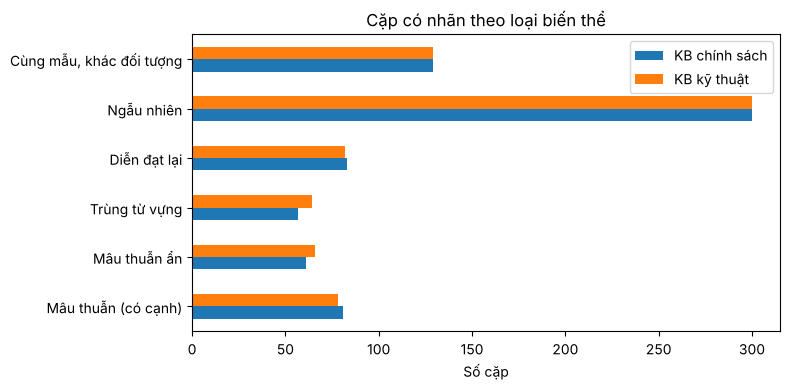

,tenant,split,n,positives
0,policy,dev,444,111
1,policy,test,124,31
2,tech,dev,472,118
3,tech,test,104,26


In [3]:
show(plots.dataset_overview(pairs), "01_dataset_overview")
pd.DataFrame(layer2["counts"])

## 2. Động lực: cosine trên ViNLI

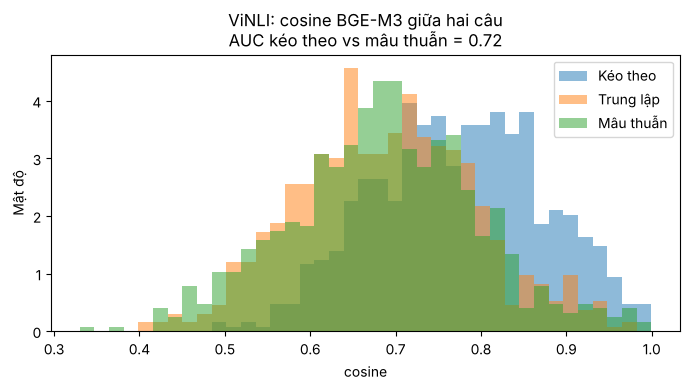

{'backend': 'bge-m3',
 'split': 'test',
 'n': 2264,
 'seconds': 263.43462628299994,
 'mean_cosine': {'contradiction': 0.6860887715984717,
  'entailment': 0.7741017838319143,
  'neutral': 0.6889188255889382},
 'auc_entailment_vs_contradiction': 0.7233649932157394,
 'auc_contradiction_vs_neutral': 0.4956264657757195}

In [4]:
vinli = read_parquet(ARTIFACTS / "vinli" / "vinli_cosine.parquet")
vinli_summary = read_json(ARTIFACTS / "vinli" / "vinli_summary.json")
show(plots.vinli_cosine(vinli, vinli_summary), "02_vinli_cosine")
vinli_summary

## 3. Layer 2: grid search λ×τ và ablation

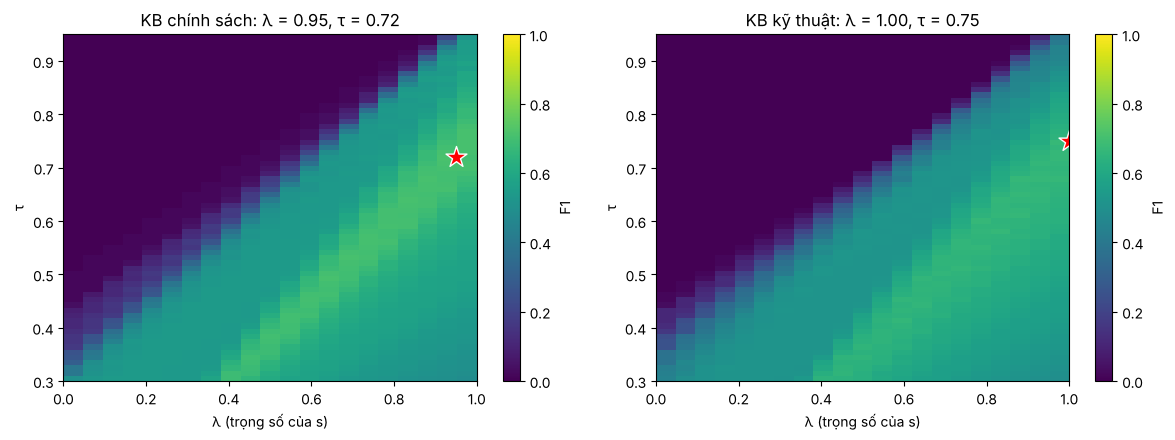

In [5]:
show(plots.tenant_heatmaps(grid, config), "03_grid_heatmaps")

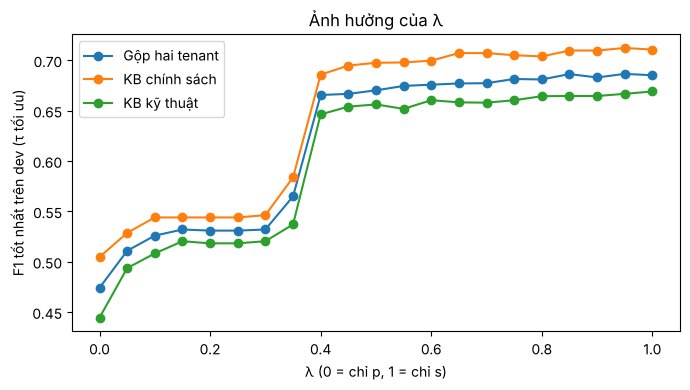

In [6]:
show(plots.lambda_profile(grid), "04_lambda_profile")

In [7]:
table = pd.DataFrame(layer2["test"])
table[["scope", "method_label", "lambda", "tau", "precision", "recall", "f1", "f1_ci95", "pr_auc"]].round(3)

,scope,method_label,lambda,tau,precision,recall,f1,f1_ci95,pr_auc
0,all,Chỉ s (λ = 1),NaN,NaN,0.543,0.772,0.638,"[0.545421, 0.728428]",0.638
1,all,Chỉ p (λ = 0),NaN,NaN,0.480,0.421,0.449,"[0.326531, 0.56672]",0.417
2,all,"Fusion, λ và τ theo tenant",NaN,NaN,0.530,0.772,0.629,"[0.534207, 0.721094]",0.620
3,all,"Fusion, λ và τ chung",NaN,NaN,0.524,0.772,0.624,"[0.524571, 0.715232]",0.631
4,policy,Chỉ s (λ = 1),1.00,0.77,0.535,0.742,0.622,"[0.474576, 0.752949]",0.652
5,policy,Chỉ p (λ = 0),0.00,0.30,0.462,0.387,0.421,"[0.255319, 0.571429]",0.427
6,policy,"Fusion, λ và τ theo tenant",0.95,0.72,0.511,0.742,0.605,"[0.472715, 0.722239]",0.635
7,policy,"Fusion, λ và τ chung",0.95,0.72,0.511,0.742,0.605,"[0.457719, 0.725]",0.635
8,tech,Chỉ s (λ = 1),1.00,0.75,0.553,0.808,0.656,"[0.515093, 0.776119]",0.631
9,tech,Chỉ p (λ = 0),0.00,0.30,0.500,0.462,0.480,"[0.294082, 0.645209]",0.425


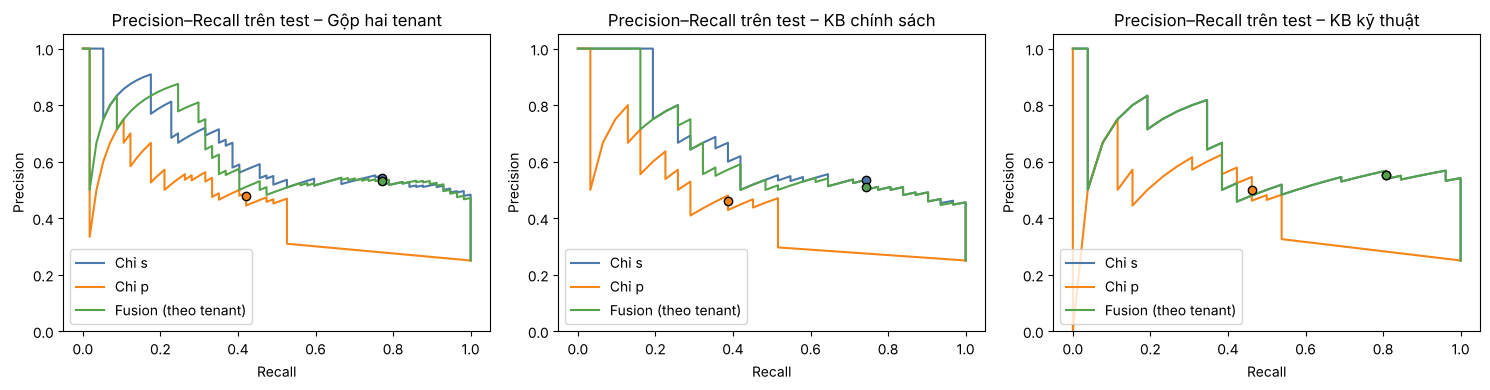

In [8]:
show(plots.pr_curves(scored), "05_pr_curves")

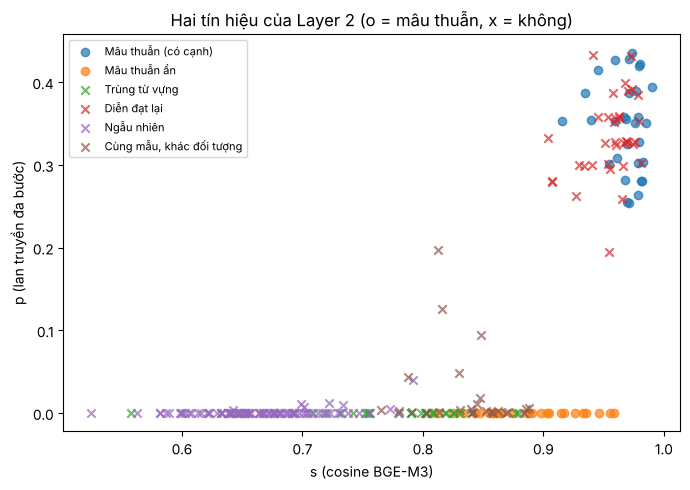

In [9]:
show(plots.signal_scatter(scored), "06_signal_scatter")

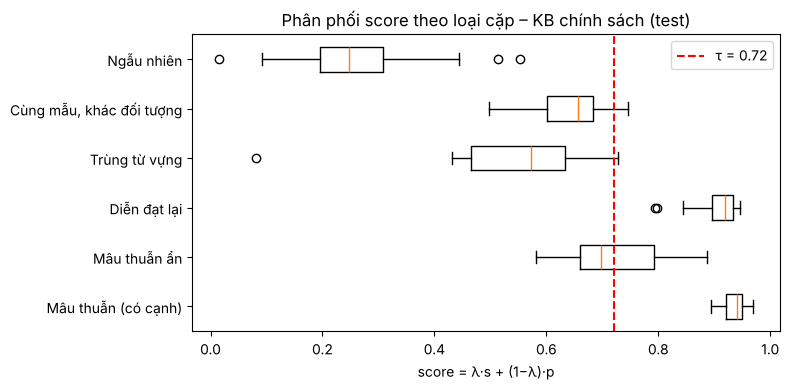

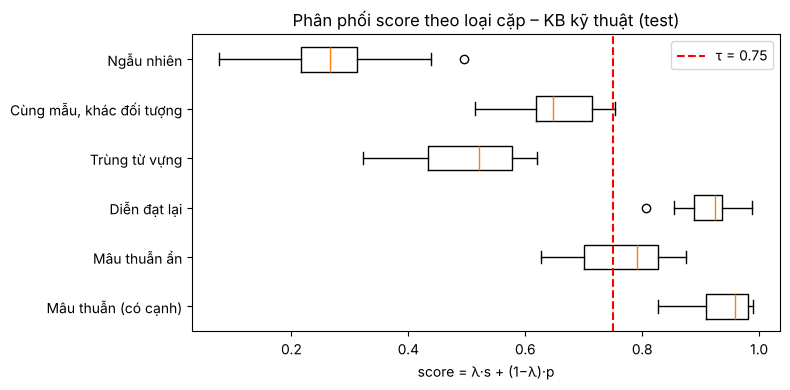

,variant_type,label,n,flagged_s_only,flagged_p_only,flagged_fusion,flagged_global,mean_s,mean_p
0,conflict,1,30,1.00,0.80,1.00,1.00,0.97,0.35
1,hidden_conflict,1,27,0.52,0.00,0.52,0.52,0.88,0.00
2,lexical_overlap,0,26,0.00,0.00,0.08,0.08,0.78,0.00
3,paraphrase,0,35,1.00,0.74,1.00,1.00,0.96,0.33
4,random,0,85,0.00,0.00,0.00,0.00,0.66,0.00
5,same_template,0,25,0.08,0.00,0.08,0.12,0.84,0.02


In [10]:
for tenant in sorted(scored.tenant.unique()):
    show(plots.score_distribution(scored, tenant), f"07_score_distribution_{tenant}")
pd.DataFrame(layer2["test_by_variant"]).round(2)

## 4. Layer 3: dự báo lỗi thời

In [11]:
pd.DataFrame(layer3["test"]).round(3)

,model,roc_auc,pr_auc,precision_at_10,precision_at_20,positives,n,ms_per_row
0,xgb_hard_labels,0.793,0.291,0.9,0.5,52,1046,0.001
1,xgb_distilled,0.803,0.312,0.9,0.6,52,1046,0.001
2,tabpfn,0.764,0.262,0.7,0.5,52,1046,57.807


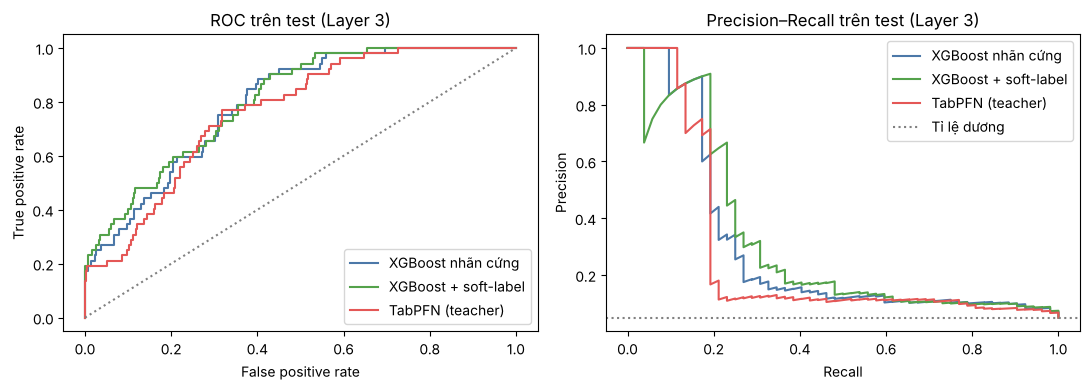

In [12]:
models = [row["model"] for row in layer3["test"]]
show(plots.forecast_curves(predictions, models), "08_forecast_curves")

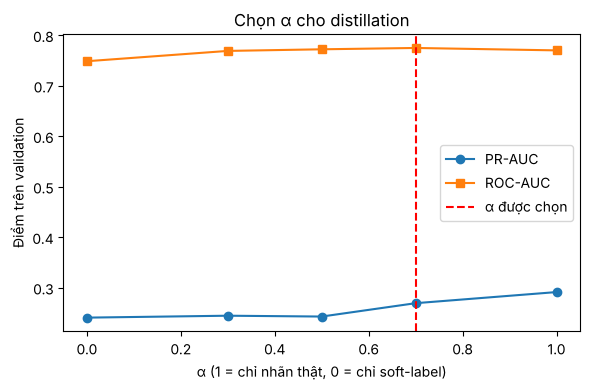

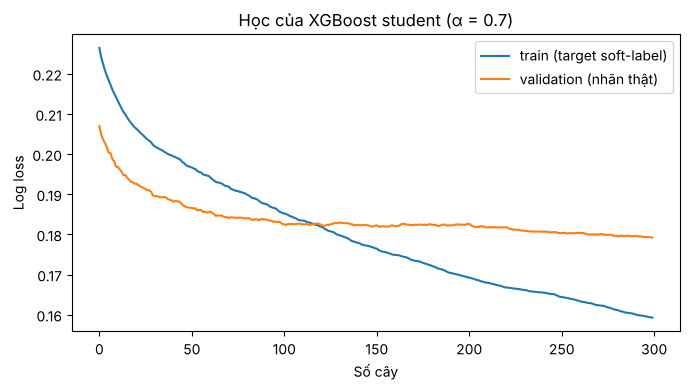

In [13]:
show(plots.alpha_selection(layer3), "09_alpha_selection")
show(plots.learning_curve(layer3), "10_learning_curve")

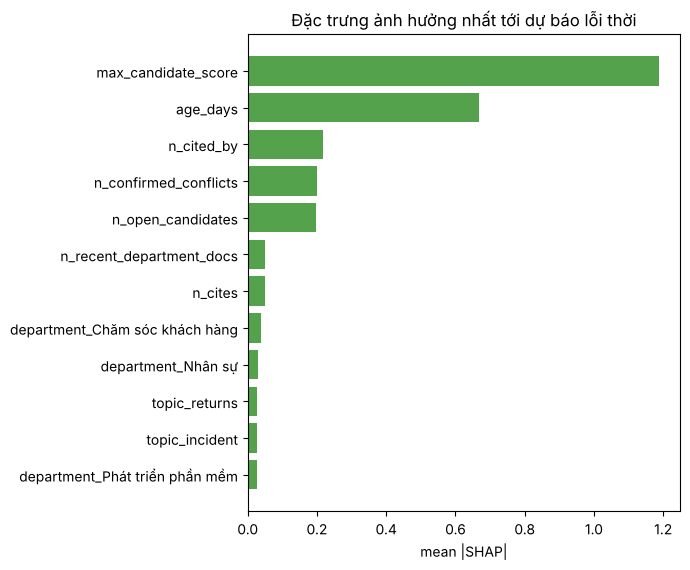

,doc_id,tenant,topic,age_days,n_open_candidates,n_confirmed_conflicts,p_obsolete
0,POL-003-v1,policy,leave,543,0,1,0.785925
1,SOP-060-v1,tech,incident,549,20,1,0.321626
2,POL-151-v1,policy,delivery,634,8,0,0.303183
3,SOP-082-v1,tech,access,498,1,0,0.301037
4,POL-070-v1,policy,returns,627,5,0,0.299371


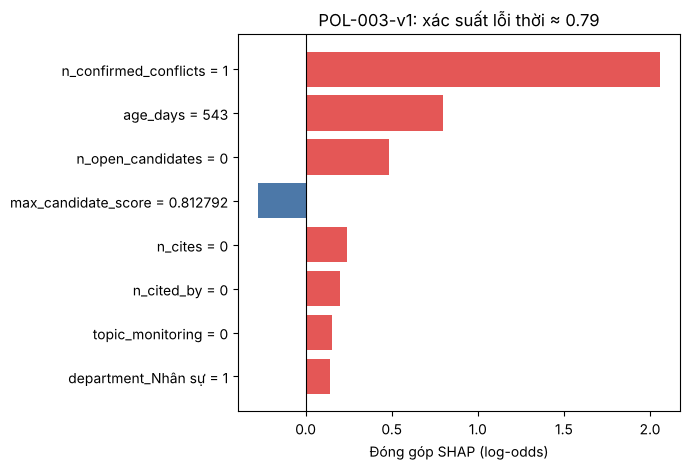

In [14]:
show(plots.shap_summary(shap_data), "11_shap_summary")
top = read_parquet(kb / "forecast_scores.parquet").head(5)
display(top[["doc_id", "tenant", "topic", "age_days", "n_open_candidates", "n_confirmed_conflicts", "p_obsolete"]])
show(plots.shap_waterfall(shap_data, top.doc_id.iloc[0]), "12_shap_waterfall")

## 5. Tuỳ chọn: tương tác

Chọn một cặp để xem s, p, score; kéo λ, τ để thấy P/R/F1 trên test thay đổi.

In [15]:
import ipywidgets as widgets
docs = read_parquet(DATA_PROCESSED / "kb_docs.parquet").set_index("doc_id")
test = scored[scored.split == "test"].reset_index(drop=True)
options = [(f"{r.doc_a} ↔ {r.doc_b} ({plots.VARIANT_LABELS[r.variant_type]})", i) for i, r in test.iterrows()]
def inspect_pair(i):
    r = test.loc[i]
    verdict = "CÓ thể mâu thuẫn" if r.pred_fusion else "không vượt ngưỡng"
    print(f"s = {r.s:.3f}  p = {r.p:.3f}  score = {r.score_fusion:.3f}  τ = {r.tau_fusion:.2f}  →  {verdict}  (nhãn thật: {r.label})")
    print(docs.loc[r.doc_a, "text"]); print("-" * 60); print(docs.loc[r.doc_b, "text"])
widgets.interact(inspect_pair, i=widgets.Dropdown(options=options, description="Cặp"))

interactive(children=(Dropdown(description='Cặp', options=(('POL-010-v1 ↔ POL-010-v2 (Mâu thuẫn (có cạnh))', 0…

<function __main__.inspect_pair(i)>

In [16]:
def tune(tenant, lam, tau):
    m = plots.threshold_metrics(scored, lam, tau, tenant=None if tenant == "all" else tenant)
    print(f"P = {m['precision']:.3f}  R = {m['recall']:.3f}  F1 = {m['f1']:.3f}   TP={m['tp']} FP={m['fp']} FN={m['fn']} TN={m['tn']}")
widgets.interact(tune, tenant=["all", "tech", "policy"],
                 lam=widgets.FloatSlider(value=config["global"]["FUSION_LAMBDA"], min=0, max=1, step=0.05, description="λ"),
                 tau=widgets.FloatSlider(value=config["global"]["CONFLICT_THRESHOLD_TAU"], min=0.3, max=0.95, step=0.01, description="τ"))

interactive(children=(Dropdown(description='tenant', options=('all', 'tech', 'policy'), value='all'), FloatSli…

<function __main__.tune(tenant, lam, tau)>